# ChromaSort: CNN-Based Color Detection & Conveyor Belt Routing
**CNN-based color classification (blue / purple / yellow)**

A small CNN, trained **from scratch** (no pretrained model) on our own 165 photographs, looks at one object and decides its color. The predicted class is mapped to a belt through a list lookup:

| Color | Belt |
|-------|------|
| Blue | Belt A |
| Yellow | Belt B |
| Purple | Belt C |

## Contents
1. Step 1: Imports, seeds, Google Drive
2. Step 2: Convert unreadable image formats (HEIC) and count images
3. Step 3: Visual check of the dataset
4. Step 4: Train / validation / test split (70/15/15 per class)
5. Step 5: Load splits as TensorFlow datasets
6. Step 6: Build the CNN
7. Step 7: Train with early stopping
8. Step 8: Training curves
9. Step 9: Test accuracy
10. Step 10: Confusion matrix and classification report
11. Step 10b: Random test predictions
12. Step 11: Save the model
13. Step 12: Belt prediction function
14. Step 13: Live demo (upload any image)

> **How to run:** open in Google Colab, put the dataset in Google Drive at `MyDrive/COLOR_DATASET/{blue,purple,yellow}`, and run the cells from top to bottom in one session. See the README for details.

---
## Step 1: Imports, seeds, Google Drive
Load the libraries, fix the random seeds (42) for repeatability, mount Google Drive, and set the dataset path. `CLASSES` is alphabetical because Keras numbers labels alphabetically: blue = 0, purple = 1, yellow = 2.

In [ ]:
# STEP 1: imports, seeds, Google Drive
import os, glob, random, shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from google.colab import drive, files

random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)      # seeds Python, NumPy and TensorFlow together

drive.mount("/content/drive")
DATA = "/content/drive/MyDrive/COLOR_DATASET"     # folder with blue/ purple/ yellow/ sub-folders
CLASSES = ["blue", "purple", "yellow"]            # alphabetical = the order Keras gives labels 0, 1, 2


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Step 2: Convert unreadable image formats and count images
iPhone photos are saved as HEIC, which TensorFlow cannot read. This cell converts any non-supported file to JPG and prints the image count per class (expected: 55 each).

In [ ]:
# STEP 2: convert unreadable image formats to JPG, then count the images
!pip install -q pillow-heif
from PIL import Image
from pillow_heif import register_heif_opener
register_heif_opener()                      # lets Pillow open iPhone HEIC photos

SUPPORTED = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
for c in CLASSES:
    bad = [f for f in glob.glob(f"{DATA}/{c}/*") if not f.lower().endswith(SUPPORTED)]
    for f in bad:
        try:
            Image.open(f).convert("RGB").save(os.path.splitext(f)[0] + ".jpg", quality=95)
            os.remove(f)                    # remove the old file so only the JPG remains
        except Exception as e:
            print("Could not convert", os.path.basename(f), "->", e)
    print(c, ":", len(glob.glob(f"{DATA}/{c}/*")), "images | converted:", len(bad))

blue : 55 images | converted: 0
purple : 55 images | converted: 0
yellow : 55 images | converted: 0


---
## Step 3: Look at sample images from each class
A quick visual check that images load correctly and sit in the right color folders. The file names show which team member (p1 to p5) took each photo.

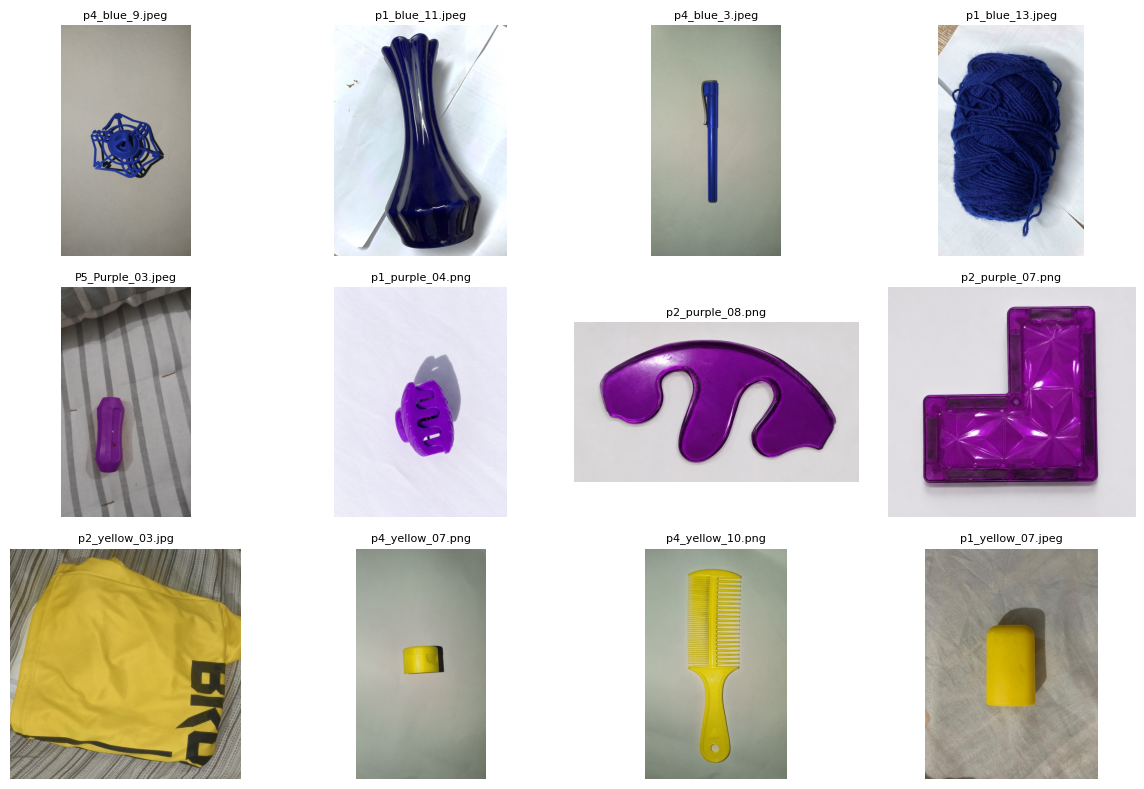

In [ ]:
# STEP 3: look at a few random images from each class
viewer = random.Random(0)          # separate generator, so Step 4's split is not affected
plt.figure(figsize=(12, 8))
n = 0
for c in CLASSES:
    files_in_class = sorted(glob.glob(f"{DATA}/{c}/*"))
    for p in viewer.sample(files_in_class, 4):
        n += 1
        plt.subplot(3, 4, n)
        plt.imshow(tf.keras.utils.load_img(p))
        plt.title(os.path.basename(p), fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()


---
## Step 4: Split every class 70% / 15% / 15%
Each color is split separately into train / validation / test, so every set stays balanced. With 55 images per class this gives 38 / 8 / 9.

In [ ]:

# STEP 4: split every class 70% train / 15% validation / 15% test
SPLIT = "/content/split"
shutil.rmtree(SPLIT, ignore_errors=True)        # delete the old split folder so re-running the cell starts clean

for c in CLASSES:
    imgs = sorted(glob.glob(f"{DATA}/{c}/*"))
    random.shuffle(imgs)
    train_end = int(len(imgs) * 0.70)
    val_end   = int(len(imgs) * 0.85)
    parts = {"train": imgs[:train_end], "val": imgs[train_end:val_end], "test": imgs[val_end:]}
    for name, items in parts.items():
        os.makedirs(f"{SPLIT}/{name}/{c}", exist_ok=True)
        for f in items:
            shutil.copy(f, f"{SPLIT}/{name}/{c}")
    print(c, "-> train:", len(parts["train"]), "val:", len(parts["val"]), "test:", len(parts["test"]))

blue -> train: 38 val: 8 test: 9
purple -> train: 38 val: 8 test: 9
yellow -> train: 38 val: 8 test: 9


---
## Step 5: Load the splits as TensorFlow datasets
Images are resized to 128x128 RGB and grouped into batches of 16. Validation and test are not shuffled so the labels and predictions line up in Step 10. The printed class order must be `['blue', 'purple', 'yellow']`.

In [ ]:

# STEP 5: load the three splits as datasets
IMG = (128, 128)
BATCH = 16

def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"{SPLIT}/{split}",
        image_size=IMG,             # every image is resized to 128x128
        batch_size=BATCH,
        label_mode="int",           # labels are 0, 1, 2
        color_mode="rgb",           # grayscale / RGBA files are converted to 3 channels
        shuffle=shuffle,
        seed=42)

train_ds = load("train", True)
val_ds   = load("val", False)
test_ds  = load("test", False)

class_names = train_ds.class_names
print("Class order:", class_names)          # must print ['blue', 'purple', 'yellow']


Found 114 files belonging to 3 classes.
Found 24 files belonging to 3 classes.
Found 27 files belonging to 3 classes.
Class order: ['blue', 'purple', 'yellow']


---
## Step 6: Build the CNN
Three Conv2D + MaxPooling blocks, then GlobalAveragePooling2D, Dropout(0.4), Dense(64) and a 3-way softmax. Trained from scratch (random initial weights), 60,675 parameters in total.

In [ ]:

# STEP 6: build the CNN (trained from scratch, no pretrained weights)
# No data augmentation: the model sees the original images only.
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Rescaling(1.0 / 255),            # pixels 0-255 -> 0-1

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),        # far fewer weights than Flatten, overfits less
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dense(3, activation="softmax")   # 3 probabilities: blue, purple, yellow
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,675 (237.01 KB)

 Trainable params: 60,675 (237.01 KB)

 Non-trainable params: 0 (0.00 B)

---
## Step 7: Train with early stopping
Up to 60 epochs, but training stops when validation loss does not improve for 10 epochs and the best weights are restored. In our run training stopped at epoch 39 (best epoch 29).

In [ ]:

# STEP 7: train, stop automatically when validation loss stops improving
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(train_ds,
                    validation_data=val_ds,
                    epochs=60,
                    callbacks=[early_stop])

Epoch 1/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 472ms/step - accuracy: 0.2632 - loss: 1.1084 - val_accuracy: 0.3333 - val_loss: 1.0810
Epoch 2/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.3509 - loss: 1.0933 - val_accuracy: 0.5000 - val_loss: 1.0474
Epoch 3/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.5263 - loss: 1.0445 - val_accuracy: 0.5000 - val_loss: 0.9965
Epoch 4/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 175ms/step - accuracy: 0.4298 - loss: 1.0256 - val_accuracy: 0.5417 - val_loss: 0.9761
Epoch 5/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 165ms/step - accuracy: 0.6053 - loss: 0.9407 - val_accuracy: 0.7917 - val_loss: 0.8864
Epoch 6/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 285ms/step - accuracy: 0.6754 - loss: 0.8494 - val_accuracy: 0.6250 - val_loss: 0.7896
Epoch 7/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 253ms/step - accuracy: 0.7368 - loss: 0.6785 - val_accuracy: 0.5000 - val_loss: 0.8694
Epoch 8/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 175ms/step - accuracy: 0.6316 - loss: 0.7214 - val_accuracy: 0.7500 - val_loss:

---
## Step 8: Training curves
Accuracy and loss per epoch for the training and validation sets.

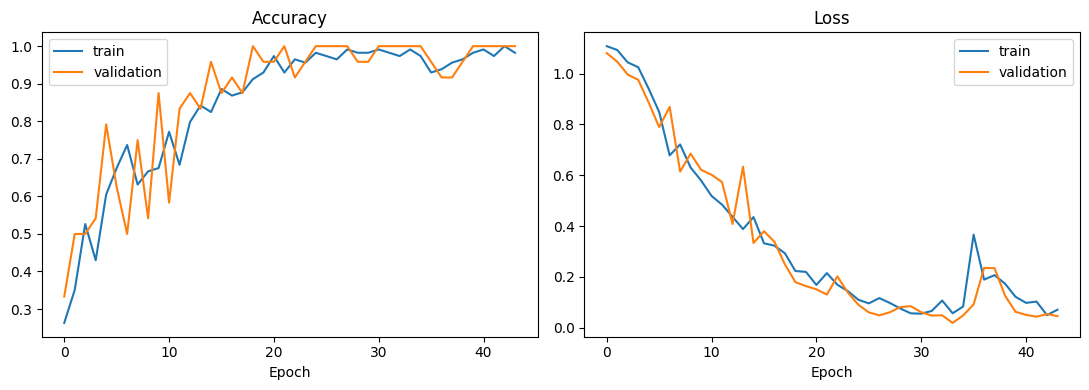

In [ ]:
# STEP 8: training curves
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()

plt.tight_layout()
plt.show()


---
## Step 9: Test accuracy
Evaluation on the 27 test images that were never used for training or for choosing the best epoch. **Test accuracy: 96.30%.**

In [ ]:
# STEP 9: TEST ACCURACY (images the model has never seen)
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}  ({test_acc*100:.2f}%)")




2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 441ms/step - accuracy: 0.9630 - loss: 0.2199
Test accuracy: 0.9630  (96.30%)


---
## Step 10: Confusion matrix and per-class report
Shows which colors get mixed up. The only mistake was one purple image predicted as yellow.

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


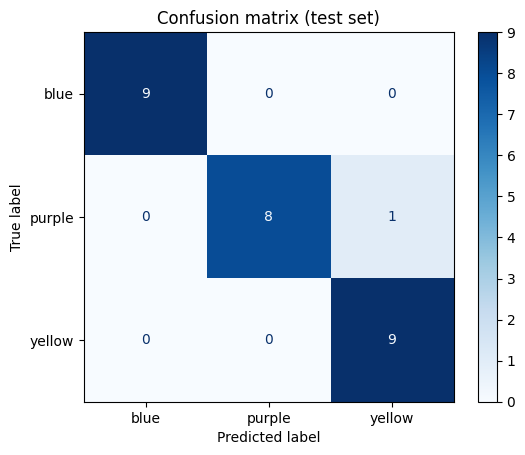

              precision    recall  f1-score   support

        blue       1.00      1.00      1.00         9
      purple       1.00      0.89      0.94         9
      yellow       0.90      1.00      0.95         9

    accuracy                           0.96        27
   macro avg       0.97      0.96      0.96        27
weighted avg       0.97      0.96      0.96        27



In [ ]:
# STEP 10: confusion matrix and per-class report
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()
print(classification_report(y_true, y_pred, target_names=class_names))





---
## Step 10b: Random test images with true and predicted color
Eight random test images with their true and predicted labels, to look at real examples.

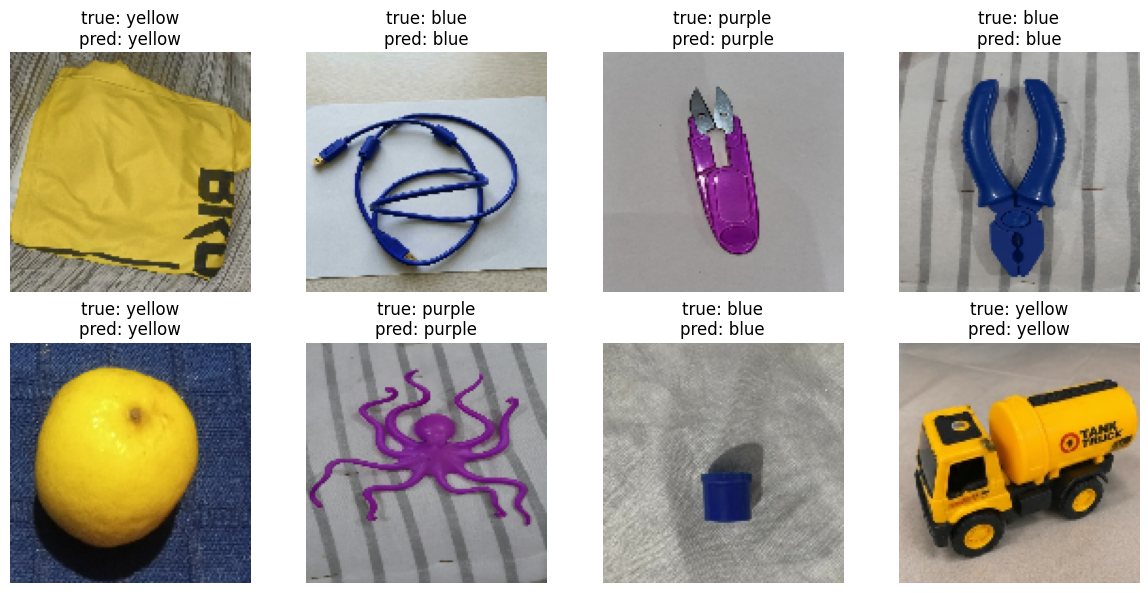

In [ ]:
# STEP 10b: show random test images with their true and predicted colour
test_images = np.concatenate([x.numpy() for x, _ in test_ds])    # all test images in one array
pick = np.random.choice(len(test_images), 8, replace=False)      # 8 random positions
pick_preds = np.argmax(model.predict(test_images[pick], verbose=0), axis=1)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(test_images[pick[i]].astype("uint8"))
    plt.title(f"true: {class_names[y_true[pick[i]]]}\npred: {class_names[pick_preds[i]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

---
## Step 11: Save the trained model
Saves the model as a `.keras` file and copies it to Google Drive, because Colab's temporary storage is wiped when the session ends.

In [ ]:
# STEP 11: save the trained model
model.save("/content/chromasort_cnn.keras")
shutil.copy("/content/chromasort_cnn.keras", "/content/drive/MyDrive/chromasort_cnn.keras")


'/content/drive/MyDrive/chromasort_cnn.keras'

---
## Step 12: Belt prediction function
`predict_belt(image_path)` loads an image, runs the saved model, and picks the belt with `np.argmax` and the `BELTS` list. The belt is chosen by indexing into a list.

In [ ]:


# STEP 12: belt prediction (a list lookup chooses the belt, no conditions needed)
model = tf.keras.models.load_model("/content/chromasort_cnn.keras")   # use the saved model for prediction
BELT_FOR_COLOR = {"blue": "Belt A", "yellow": "Belt B", "purple": "Belt C"}
BELTS = [BELT_FOR_COLOR[name] for name in class_names]   # index 0 -> A, 1 -> C, 2 -> B

def predict_belt(image_path):
    img = tf.keras.utils.load_img(image_path, target_size=IMG, interpolation="bilinear")    # same size, RGB and resizing method as training
    arr = tf.keras.utils.img_to_array(img)[np.newaxis, ...]       # shape (1, 128, 128, 3)
    probs = model.predict(arr, verbose=0)[0]                      # 3 probabilities
    idx = int(np.argmax(probs))                                   # most likely class index
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[idx].upper()} ({probs[idx]*100:.1f}%) -> {BELTS[idx]}")
    plt.show()
    print(f"{os.path.basename(image_path)}: colour = {class_names[idx]}, send to {BELTS[idx]}")
    return BELTS[idx]


---
## Step 13: Live demo, upload any image
Run this cell, click **Choose Files**, and select one or more images. The predicted color, confidence and belt are shown for each. The model only knows three colors, so it always picks one of the three belts, whatever the object is.

Saving images.jpg to images.jpg
Saving images (2).jpg to images (2).jpg
Saving images (1).jpg to images (1).jpg


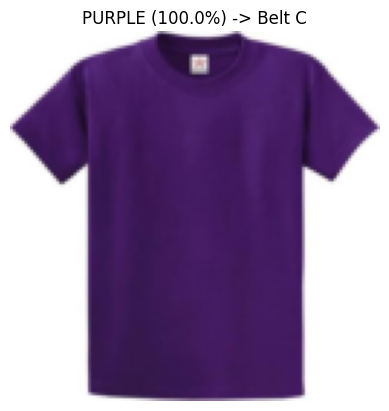

images.jpg: colour = purple, send to Belt C


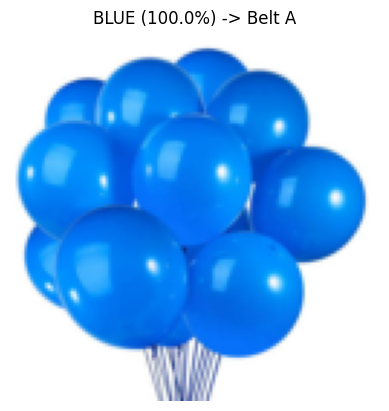

images (2).jpg: colour = blue, send to Belt A


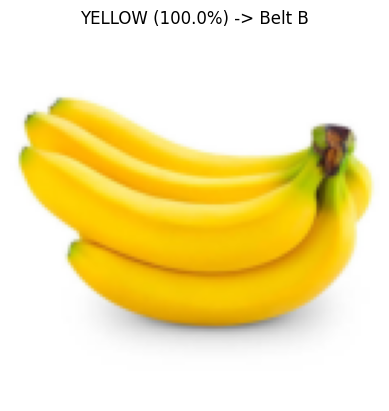

images (1).jpg: colour = yellow, send to Belt B


In [ ]:


# STEP 13: evaluator uploads any image(s) and gets the belt
uploaded = files.upload()
for name in uploaded:
    predict_belt(name)